## 1. Wczytanie danych i funkcje pomocnicze

Osiem tabel jednego meczu z `output/` (używamy tylko `formations` i `team_stats`) oraz **wspólna tabela wszystkich meczów** `events_all` wczytywana z `output/combined/combined_events.csv`, na której pracują sekcje 2–9 i 12–14. Tu też funkcje używane dalej (`wilson_ci`, `cond_table`, `plane_r2`).


In [44]:
# Wczytanie: tabele JEDNEGO meczu (formacje, statystyki) + wspolna tabela wszystkich meczow
from pathlib import Path

import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent
DATA = ROOT / "output"
COMBINED = DATA / "combined"
FIGURES = DATA / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# jeden mecz - do wizualizacji per-mecz (sekcje 10-11)
MATCH = "match_1821123_Southampton_vs_Aston_Villa"

# wszystkie tabele, jakie produkuje scraper, trzymamy w jednym slowniku
match_tables = {
    name: pd.read_csv(DATA / f"{MATCH}_{name}.csv")
    for name in [
        "players",
        "metadata",
        "formations",
        "lookups",
        "minute_mapping",
        "player_stats",
        "shot_zones",
        "team_stats",
    ]
}

# dalej uzywamy tylko tych dwoch - reszta sluzy jako przeglad danych
formations = match_tables["formations"]
team_stats = match_tables["team_stats"]

print("mecz do wizualizacji:", MATCH)
for name, table in match_tables.items():
    print(f"  {name:<16} {str(table.shape):>14}")


mecz do wizualizacji: match_1821123_Southampton_vs_Aston_Villa
  players                (40, 23)
  metadata                (1, 58)
  formations            (158, 21)
  lookups                (243, 3)
  minute_mapping         (100, 4)
  player_stats          (4785, 9)
  shot_zones              (27, 8)
  team_stats            (1462, 7)


In [45]:
# Wszystkie mecze w jednej tabeli z output/combined/ - na niej pracuja sekcje 2-9 oraz 12-14
combined_events_path = COMBINED / "combined_events.csv"
if combined_events_path.exists():
    events_all = pd.read_csv(combined_events_path)
else:
    event_files = sorted(DATA.glob("*_events.csv"))
    events_all = pd.concat([pd.read_csv(f) for f in event_files], ignore_index=True)

n_matches = events_all["match_id"].nunique()

print("meczow:", n_matches)
print("zdarzen razem:", len(events_all))
print("kolumn:", len(events_all.columns))
print()
print("zduplikowane wiersze:", events_all.duplicated().sum())
print("kolizje id          :", events_all["id"].duplicated().sum())


meczow: 10
zdarzen razem: 16249
kolumn: 95

zduplikowane wiersze: 0
kolizje id          : 4


In [46]:
# Funkcje pomocnicze uzywane w dalszych sekcjach (zdefiniowane raz, na gorze)
def wilson_ci(k, n):
    """95% przedzial ufnosci Wilsona dla proporcji, w procentach."""
    if n == 0:
        return 0.0, 0.0
    z = 1.96
    p = k / n
    denom = 1 + z ** 2 / n
    center = (p + z ** 2 / (2 * n)) / denom
    half_width = z * ((p * (1 - p) / n + z ** 2 / (4 * n ** 2)) ** 0.5) / denom
    return 100 * (center - half_width), 100 * (center + half_width)


def cond_table(df, col, target="has_shot"):
    """P(target | col) z 95% przedzialem ufnosci Wilsona."""
    summary = df.groupby(col, observed=False).agg(
        cases=(target, "size"),
        hits=(target, "sum"),
    )
    summary["P %"] = (100 * summary["hits"] / summary["cases"]).round(2)

    intervals = []
    for k, n in zip(summary["hits"], summary["cases"]):
        low, high = wilson_ci(k, n)
        intervals.append(f"{low:.1f}-{high:.1f}")

    summary["95% CI"] = intervals
    return summary


def plane_r2(df, x1, x2, y):
    """R2 dopasowania plaszczyzny najmniejszych kwadratow y ~ x1 + x2."""
    X = np.column_stack([np.ones(len(df)), df[x1], df[x2]])
    y_true = df[y].to_numpy()

    beta, *_ = np.linalg.lstsq(X, y_true, rcond=None)
    y_pred = X @ beta

    ss_res = ((y_true - y_pred) ** 2).sum()
    ss_tot = ((y_true - y_true.mean()) ** 2).sum()
    return 1 - ss_res / ss_tot


print("dostepne funkcje: wilson_ci(), cond_table(), plane_r2()")


dostepne funkcje: wilson_ci(), cond_table(), plane_r2()


## 2. Cechy przestrzenne

Kolumny pochodne dopisywane do `events_all`: dystans do bramki, pole karne, złota strefa, strzał celny.


In [47]:
# Cechy przestrzenne - KOLUMNY POCHODNE dopisywane do events_all (nie osobne tabele).
# Wartosci x, y sa w skali 0-100; bramka przeciwnika to punkt (100, 50).
events_all["goal_distance"] = np.hypot(100 - events_all["x"], 50 - events_all["y"])

# Pole karne: x >= 83 ORAZ y w [21, 79]. Samo x >= 83 lapie tez zdarzenia
# za linia koncowa po bokach (627 z 1306 takich zdarzen w jednym meczu).
events_all["in_box"] = (events_all["x"] >= 83) & (events_all["y"].between(21, 79))

# Zlota strefa - bezposrednio przed bramka.
events_all["golden_zone"] = (events_all["x"] >= 88) & (events_all["y"].between(36, 64))

# Strzal celny: gol albo obrona bramkarza.
events_all["shot_on_target"] = events_all["event_type"].isin(["Goal", "SavedShot"])

print("dystans do bramki : min %.1f  max %.1f" % (
    events_all["goal_distance"].min(),
    events_all["goal_distance"].max(),
))
print("zdarzen w polu karnym   :", int(events_all["in_box"].sum()))
print("zdarzen w zlotej strefie:", int(events_all["golden_zone"].sum()))
print("strzalow celnych        :", int(events_all["shot_on_target"].sum()))


dystans do bramki : min 0.9  max 111.8
zdarzen w polu karnym   : 690
zdarzen w zlotej strefie: 224
strzalow celnych        : 180


## 3. Selekcja kolumn do analizy zależności

Usuwa identyfikatory, flagi 0/1, kolumny o niskim pokryciu i duplikaty informacyjne.


In [48]:
# Selekcja kolumn do analizy zaleznosci (na wszystkich meczach)
# identyfikatory, kategorie i duplikaty informacyjne - bez sensu w korelacjach
EXCLUDED_COLS = [
    "match_id", "event_index", "id", "event_id",
    "team_id", "player_id", "related_event_id",
    "opposite_related_event_id", "next_team_id", "next_player_id",
    "receiver_id", "minute", "shirt_no", "period_value",
    "event_field", "minute_info_minute", "minute_info_expanded_minute",
    "minute_info_period", "minute_info_extra_time",
]

MIN_COVERAGE = 0.5

selected_cols = []
for col in events_all.select_dtypes("number").columns:
    if col in EXCLUDED_COLS:
        continue
    if events_all[col].notna().mean() < MIN_COVERAGE:
        continue
    if events_all[col].dropna().isin([0, 1]).all():
        continue
    selected_cols.append(col)

# usun kolumny niosace te sama informacje (|r| > 0.99)
unique_cols = []
for col in selected_cols:
    for kept in unique_cols:
        if abs(events_all[col].corr(events_all[kept])) > 0.99:
            print(f"  pomijam {col}: to samo co {kept}")
            break
    else:
        unique_cols.append(col)

selected_cols = unique_cols

print()
print("kolumny do analizy:", len(selected_cols))
for col in selected_cols:
    coverage = 100 * events_all[col].notna().mean()
    print(f"  {col:<26} pokrycie {coverage:5.1f}%")


  pomijam qualifier_pass_end_x: to samo co end_x
  pomijam qualifier_pass_end_y: to samo co end_y

kolumny do analizy: 10
  second                     pokrycie  99.8%
  expanded_minute            pokrycie 100.0%
  event_type_value           pokrycie 100.0%
  x                          pokrycie 100.0%
  y                          pokrycie 100.0%
  end_x                      pokrycie  68.4%
  end_y                      pokrycie  68.4%
  pass_length                pokrycie  68.2%
  pass_angle                 pokrycie  68.2%
  goal_distance              pokrycie 100.0%


## 4. Macierz korelacji

Korelacje Spearmana między kolumnami na wszystkich meczach.


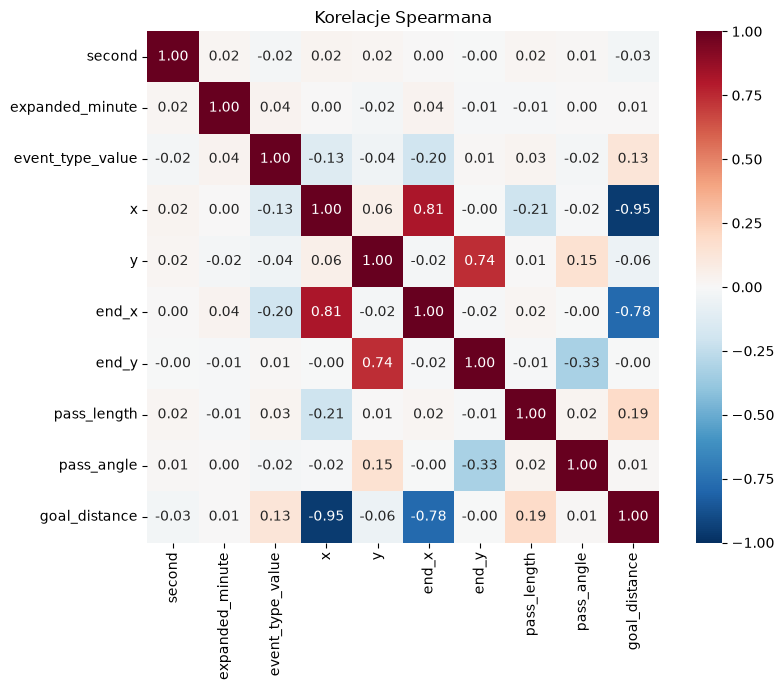

najsilniejsze pary:
  x                        <-> goal_distance            r = -0.955
  x                        <-> end_x                    r = +0.814
  end_x                    <-> goal_distance            r = -0.777
  y                        <-> end_y                    r = +0.738
  end_y                    <-> pass_angle               r = -0.325
  x                        <-> pass_length              r = -0.209
  event_type_value         <-> end_x                    r = -0.201
  pass_length              <-> goal_distance            r = +0.193

UWAGA: zwiazki z 'goal_distance' wynikaja z geometrii -
dystans jest wyliczany z x i y, wiec korelacja jest z definicji.


In [49]:
# Macierz korelacji Spearmana miedzy wybranymi kolumnami (wszystkie mecze)
corr_matrix = events_all[selected_cols].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Korelacje Spearmana")
plt.tight_layout()
plt.savefig(FIGURES / "korelacje.png", dpi=130)
plt.show()

pairs = []
for a, b in itertools.combinations(selected_cols, 2):
    pairs.append((a, b, corr_matrix.loc[a, b]))
pairs.sort(key=lambda t: -abs(t[2]))

print("najsilniejsze pary:")
for a, b, r in pairs[:8]:
    print(f"  {a:<24} <-> {b:<24} r = {r:+.3f}")
print()
print("UWAGA: zwiazki z 'goal_distance' wynikaja z geometrii -")
print("dystans jest wyliczany z x i y, wiec korelacja jest z definicji.")


## 5. Ranking trójek (R² płaszczyzny)

Dla każdej trójki kolumn dopasowujemy płaszczyznę najmniejszych kwadratów — sprawdzamy trzy możliwe kierunki i bierzemy najlepszy R². Ranking + podsumowanie wizualne par i trójek.


In [50]:
# Ranking trojek na wszystkich meczach: dla kazdej trojki dopasowujemy plaszczyzne.
# Funkcja plane_r2 jest zdefiniowana w sekcji 1.
triplets = []
for a, b, c in itertools.combinations(selected_cols, 3):
    sub_df = events_all[[a, b, c]].dropna()
    if len(sub_df) < 50:
        continue

    # sprawdzamy wszystkie trzy kierunki, bierzemy najlepszy
    best_triplet = (0.0, c, a, b)
    for target_col in (a, b, c):
        other_cols = [k for k in (a, b, c) if k != target_col]
        r2 = plane_r2(sub_df, other_cols[0], other_cols[1], target_col)
        if r2 > best_triplet[0]:
            best_triplet = (r2, target_col, other_cols[0], other_cols[1])

    triplets.append(best_triplet)

triplets.sort(key=lambda t: -t[0])

print(f"sprawdzono trojek: {len(triplets)}")
print()
print("TOP 10:")
for r2, target_col, x1, x2 in triplets[:10]:
    print(f"  {target_col:<24} ~ {x1:<22} + {x2:<22} R2 = {r2:.4f}")
print()
print("UWAGA: trojki z 'goal_distance' sa zalezne geometrycznie od x i y -")
print("R2 ~ 0.89 wynika z definicji dystansu, nie z gry.")


sprawdzono trojek: 120

TOP 10:
  goal_distance            ~ x                      + y                      R2 = 0.8904
  goal_distance            ~ second                 + x                      R2 = 0.8898
  goal_distance            ~ expanded_minute        + x                      R2 = 0.8898
  x                        ~ event_type_value       + goal_distance          R2 = 0.8897
  x                        ~ end_x                  + goal_distance          R2 = 0.8817
  goal_distance            ~ x                      + pass_length            R2 = 0.8571
  x                        ~ end_y                  + goal_distance          R2 = 0.8566
  x                        ~ pass_angle             + goal_distance          R2 = 0.8566
  x                        ~ end_x                  + pass_length            R2 = 0.7713
  end_y                    ~ y                      + pass_angle             R2 = 0.7670

UWAGA: trojki z 'goal_distance' sa zalezne geometrycznie od x i y -
R2 ~ 0.89

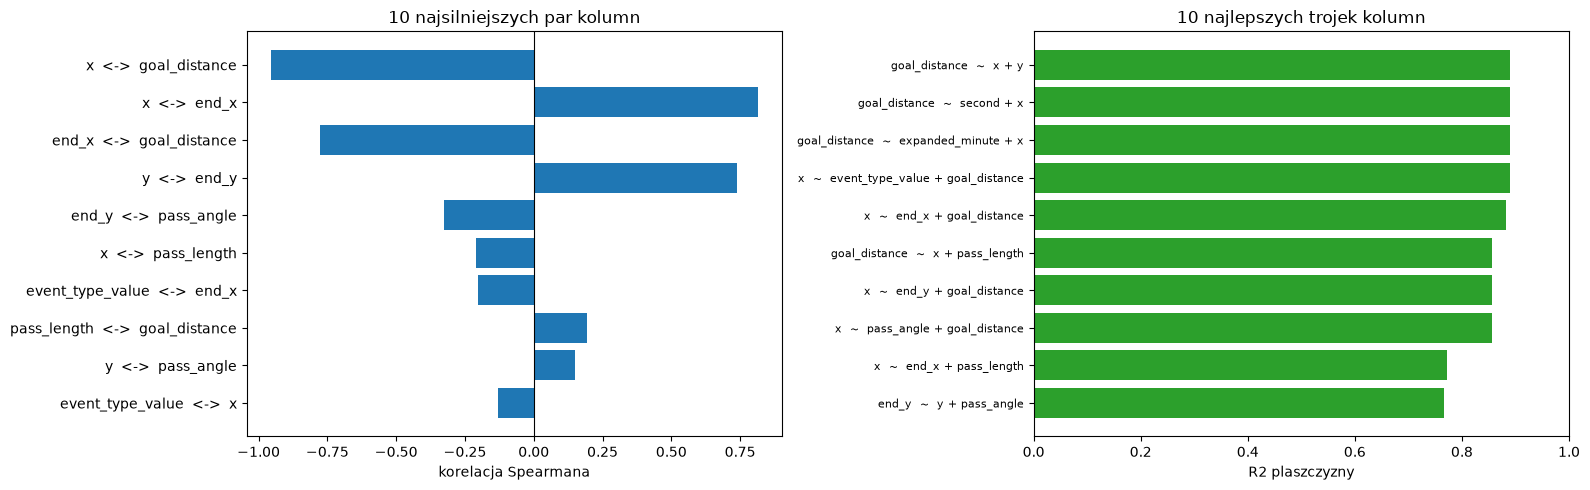

In [51]:
# Podsumowanie wizualne sekcji 4 i 5: najsilniejsze pary i najlepsze trojki obok siebie
fig, (left_ax, right_ax) = plt.subplots(1, 2, figsize=(16, 5))

# --- lewy panel: pary ---
top_pairs = pairs[:10]
left_ax.barh(
    [f"{a}  <->  {b}" for a, b, _ in top_pairs][::-1],
    [r for _, _, r in top_pairs][::-1],
)
left_ax.axvline(0, color="black", linewidth=0.8)
left_ax.set_xlabel("korelacja Spearmana")
left_ax.set_title("10 najsilniejszych par kolumn")

# --- prawy panel: trojki ---
top_triplets = triplets[:10]
right_ax.barh(
    [f"{target_col}  ~  {x1} + {x2}" for r2, target_col, x1, x2 in top_triplets][::-1],
    [r2 for r2, _, _, _ in top_triplets][::-1],
    color="tab:green",
)
right_ax.set_xlabel("R2 plaszczyzny")
right_ax.set_title("10 najlepszych trojek kolumn")
right_ax.set_xlim(0, 1)
right_ax.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.savefig(FIGURES / "pary_i_trojki.png", dpi=130)
plt.show()


## 6. Wykresy 3D

Cztery najlepsze trójki: punkty + dopasowana płaszczyzna.


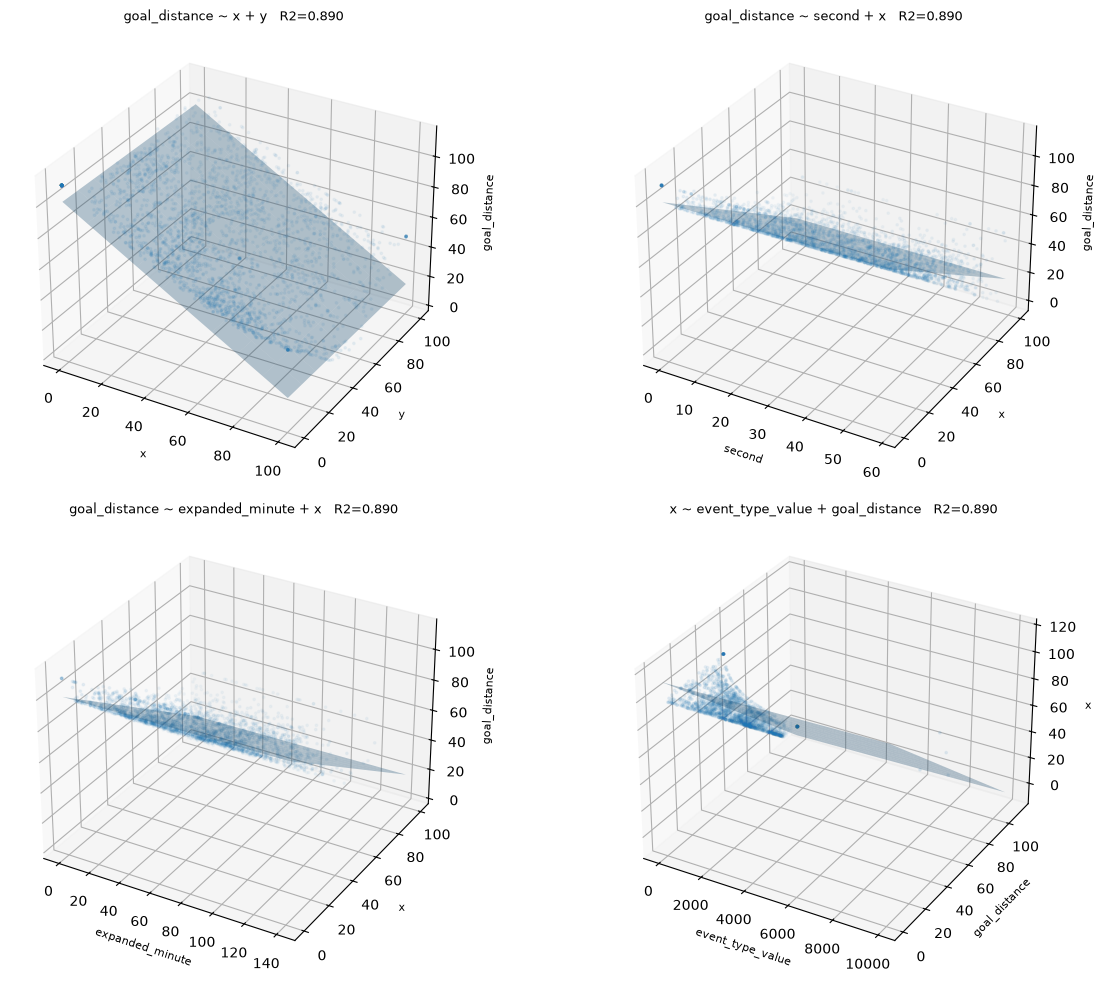

In [52]:
# Cztery najlepsze trojki na jednej figurze 2x2 - punkty + dopasowana plaszczyzna
# Regresja liczona na WSZYSTKICH punktach, do rysowania probka (16 tys. punktow to plama).
SAMPLE_SIZE = 2500

fig = plt.figure(figsize=(13, 10))

for idx, (r2, target_col, x1, x2) in enumerate(triplets[:4], start=1):
    sub_df = events_all[[x1, x2, target_col]].dropna()

    # dopasowanie na pelnych danych
    X = np.column_stack([np.ones(len(sub_df)), sub_df[x1], sub_df[x2]])
    beta, *_ = np.linalg.lstsq(X, sub_df[target_col].to_numpy(), rcond=None)

    ax = fig.add_subplot(2, 2, idx, projection="3d")

    # rysowanie na probce
    sample_df = sub_df.sample(min(SAMPLE_SIZE, len(sub_df)), random_state=42)
    ax.scatter(sample_df[x1], sample_df[x2], sample_df[target_col], s=3, alpha=0.3)

    xs = np.linspace(sub_df[x1].min(), sub_df[x1].max(), 10)
    ys = np.linspace(sub_df[x2].min(), sub_df[x2].max(), 10)
    grid_x, grid_y = np.meshgrid(xs, ys)
    grid_z = beta[0] + beta[1] * grid_x + beta[2] * grid_y
    ax.plot_surface(grid_x, grid_y, grid_z, alpha=0.3)

    ax.set_xlabel(x1, fontsize=8)
    ax.set_ylabel(x2, fontsize=8)
    ax.set_zlabel(target_col, fontsize=8)
    ax.set_title(f"{target_col} ~ {x1} + {x2}   R2={r2:.3f}", fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES / "trojki_3d.png", dpi=110)
plt.show()


## 7. Rekonstrukcja posiadania

Posiadanie = ciąg kolejnych zdarzeń tej samej drużyny w tym samym meczu. Bez serii rzutów karnych (period 5) i zdarzeń przed/po meczu.


In [53]:
# Rekonstrukcja posiadania na wszystkich meczach (poziom analizy, na ktorym dane maja sens).
ev = events_all.copy()
ev = ev.sort_values(["match_id", "event_index"]).reset_index(drop=True)

# bez serii rzutow karnych (period 5) i bez zdarzen przed/po meczu (14, 16)
n_before = len(ev)
ev = ev[~ev["period_value"].isin([5, 14, 16])]
ev = ev[ev["team_id"].notna()]
print(f"zdarzen po odfiltrowaniu: {len(ev)} (usunieto {n_before - len(ev)})")
print()

ev["has_goal"] = ev["is_goal"] == True
ev["has_shot"] = ev["is_shot"] == True
ev["is_pass"] = ev["event_type"] == "Pass"

# posiadanie = ciag kolejnych zdarzen tej samej druzyny W TYM SAMYM MECZU.
# Warunek na match_id jest konieczny - inaczej ostatni event meczu A klei sie
# z pierwszym eventem meczu B.
team_change = ev["team_id"] != ev["team_id"].shift()
match_change = ev["match_id"] != ev["match_id"].shift()
ev["possession_id"] = (team_change | match_change).cumsum()

# pole karne: x >= 83 ORAZ y w [21, 79]; bez zdarzen strzalu (zeby uniknac tautologii)
ev["in_box"] = (ev["x"] >= 83) & (ev["y"].between(21, 79))
ev["box_entry"] = ev["in_box"] & (~ev["has_shot"])

possessions = ev.groupby(["match_id", "possession_id"]).agg(
    events_count=("event_index", "size"),
    passes_count=("is_pass", "sum"),
    start_x=("x", "first"),
    box_entry=("box_entry", "max"),
    has_shot=("has_shot", "max"),
    has_goal=("has_goal", "max"),
).reset_index()

print("posiadan:", len(possessions))
print("ze strzalem:", int(possessions["has_shot"].sum()))
print("z golem:", int(possessions["has_goal"].sum()))
print()
print(f"P(has_shot | possession) = {100 * possessions['has_shot'].mean():.2f}%")
print(f"P(has_goal | possession) = {100 * possessions['has_goal'].mean():.2f}%")


zdarzen po odfiltrowaniu: 16184 (usunieto 65)

posiadan: 5074
ze strzalem: 262
z golem: 36

P(has_shot | possession) = 5.16%
P(has_goal | possession) = 0.71%


## 8. Co zwiększa szansę na strzał

Prawdopodobieństwa warunkowe z 95% przedziałami ufności Wilsona.


In [54]:
# Warunkowe prawdopodobienstwa P(has_shot | cecha posiadania)
# Funkcje wilson_ci() i cond_table() sa zdefiniowane w sekcji 1.
possessions["passes_bin"] = pd.cut(
    possessions["passes_count"],
    [-1, 0, 1, 2, 4, 8, 100],
    labels=["0", "1", "2", "3-4", "5-8", "9+"],
)
possessions["start_zone"] = pd.cut(
    possessions["start_x"],
    [0, 33, 66, 100],
    labels=["own_third", "mid_third", "final_third"],
)

for col in ["box_entry", "passes_bin", "start_zone"]:
    print(f"=== P(has_shot) wg {col} ===")
    print(cond_table(possessions, col, target="has_shot").to_string())
    print()


=== P(has_shot) wg box_entry ===
           cases  hits    P %    95% CI
box_entry                              
False       4625   211   4.56   4.0-5.2
True         449    51  11.36  8.7-14.6

=== P(has_shot) wg passes_bin ===
            cases  hits   P %    95% CI
passes_bin                             
0            2378   105  4.42   3.7-5.3
1             993    45  4.53   3.4-6.0
2             456    21  4.61   3.0-6.9
3-4           486    30  6.17   4.4-8.7
5-8           435    33  7.59  5.5-10.5
9+            326    28  8.59  6.0-12.1

=== P(has_shot) wg start_zone ===
             cases  hits    P %     95% CI
start_zone                                
own_third     1976    30   1.52    1.1-2.2
mid_third     1849    55   2.97    2.3-3.9
final_third   1129   176  15.59  13.6-17.8



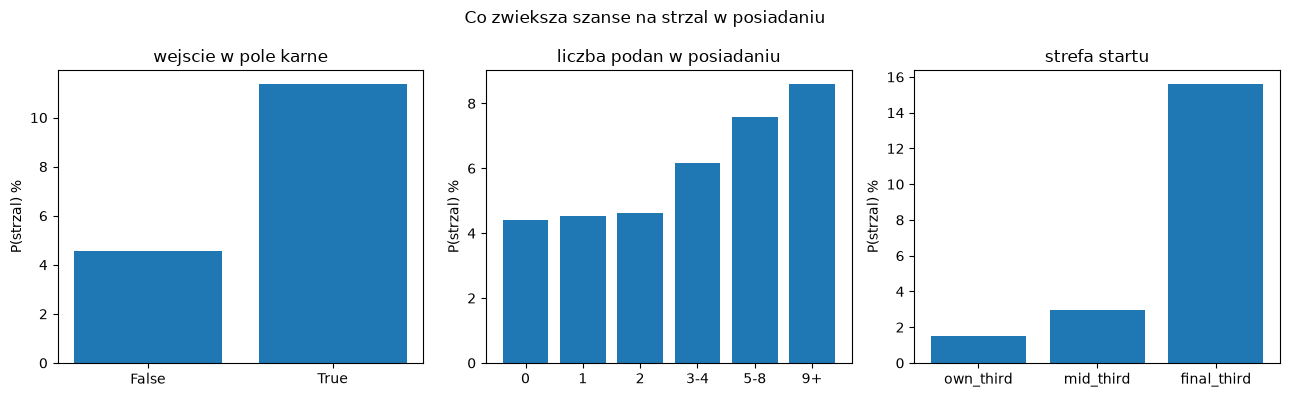

In [55]:
# Trzy panele: co zwieksza szanse na strzal
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, col, title in [
    (axes[0], "box_entry", "wejscie w pole karne"),
    (axes[1], "passes_bin", "liczba podan w posiadaniu"),
    (axes[2], "start_zone", "strefa startu"),
]:
    summary_df = cond_table(possessions, col, target="has_shot")
    ax.bar([str(i) for i in summary_df.index], summary_df["P %"])
    ax.set_title(title)
    ax.set_ylabel("P(strzal) %")

plt.suptitle("Co zwieksza szanse na strzal w posiadaniu")
plt.tight_layout()
plt.savefig(FIGURES / "posiadanie_strzal.png", dpi=130)
plt.show()


## 9. Które podania kończą się strzałem

Analiza na poziomie pojedynczego podania: strefa zakończenia i typ podania.


In [56]:
# Poziom podania: ktore podania koncza sie strzalem w tej samej akcji
ev["shot_event_idx"] = ev["event_index"].where(ev["has_shot"])
ev["shot_event_idx"] = ev.groupby(["match_id", "possession_id"])["shot_event_idx"].transform("max")

passes_df = ev[ev["is_pass"] & (ev["outcome_type"] == "Successful")].copy()
passes_df["leads_to_shot"] = passes_df["shot_event_idx"] > passes_df["event_index"]

passes_df["end_zone"] = pd.cut(
    passes_df["end_x"],
    [0, 33, 66, 83, 100],
    labels=["own_third", "mid_third", "final_third", "penalty_box"],
)

print("podan celnych:", len(passes_df))
print("z nich konczy sie strzalem:", int(passes_df["leads_to_shot"].sum()))
print(f"bazowo: {100 * passes_df['leads_to_shot'].mean():.2f}%")
print()
print("=== wg strefy, w ktorej konczy sie podanie ===")
print(cond_table(passes_df, "end_zone", target="leads_to_shot").to_string())
print()
print("=== wg typu podania ===")
for col in ["is_through_ball", "is_cross"]:
    print(f"-- {col}")
    print(cond_table(passes_df, col, target="leads_to_shot").to_string())
    print()


podan celnych: 8887
z nich konczy sie strzalem: 743
bazowo: 8.36%

=== wg strefy, w ktorej konczy sie podanie ===
             cases  hits    P %     95% CI
end_zone                                  
own_third     2283   111   4.86    4.1-5.8
mid_third     4444   281   6.32    5.6-7.1
final_third   1629   215  13.20  11.6-14.9
penalty_box    531   136  25.61  22.1-29.5

=== wg typu podania ===
-- is_through_ball
                 cases  hits    P %     95% CI
is_through_ball                               
False             8866   732   8.26    7.7-8.8
True                21    11  52.38  32.4-71.7

-- is_cross
          cases  hits    P %     95% CI
is_cross                               
False      8825   713   8.08    7.5-8.7
True         62    30  48.39  36.4-60.6



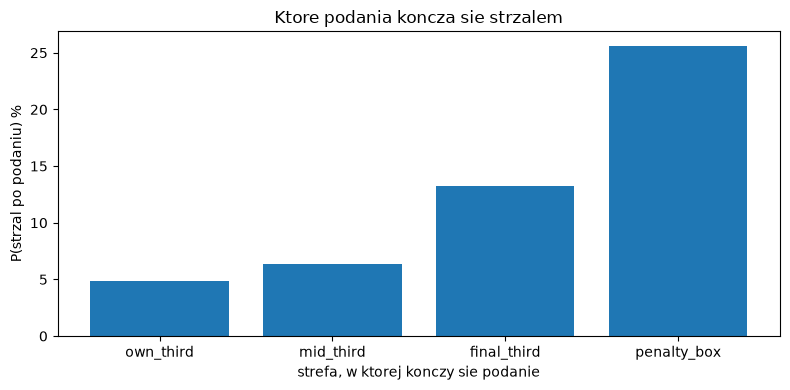

liczebnosci:
             cases  hits
end_zone                
own_third     2283   111
mid_third     4444   281
final_third   1629   215
penalty_box    531   136


In [57]:
# Wykres: P(strzal po podaniu) wg strefy zakonczenia podania
summary_df = cond_table(passes_df, "end_zone", target="leads_to_shot")

plt.figure(figsize=(8, 4))
plt.bar([str(i) for i in summary_df.index], summary_df["P %"])
plt.ylabel("P(strzal po podaniu) %")
plt.xlabel("strefa, w ktorej konczy sie podanie")
plt.title("Ktore podania koncza sie strzalem")
plt.tight_layout()
plt.savefig(FIGURES / "podania_strzal.png", dpi=130)
plt.show()

print("liczebnosci:")
print(summary_df[["cases", "hits"]].to_string())


## 10. Pozycje z formacji

Ustawienie wyjściowe obu drużyn z tabeli `formations` (skala 0–10 przeskalowana do 0–100). Uwaga na osie: w tej tabeli wzdłuż boiska idzie `vertical` (0 = własna bramka), a `horizontal` to szerokość — odwrotnie niż w zdarzeniach, gdzie wzdłuż boiska idzie `x`.


formacje w meczu: [ 343  352 4231]
zawodnikow w ustawieniu wyjsciowym: 22


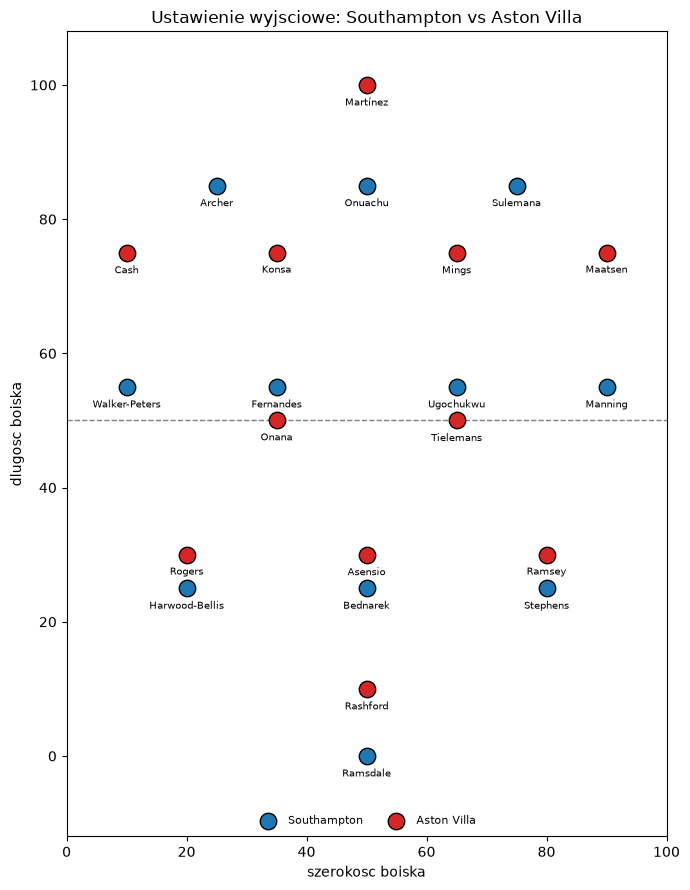

In [58]:
# Pozycje z formacji - ustawienie wyjsciowe obu druzyn (jeden mecz, tabela 'formations' z sekcji 1)
starting_lineup = formations[
    (formations["start_minute_expanded"] == 0) & (formations["slot_number"] > 0)
]

print("formacje w meczu:", formations["formation_name"].unique())
print("zawodnikow w ustawieniu wyjsciowym:", len(starting_lineup))

fig, ax = plt.subplots(figsize=(7, 9))
side_colors = {"home": "tab:blue", "away": "tab:red"}

for side in ["home", "away"]:
    side_df = starting_lineup[starting_lineup["team_side"] == side]

    # horizontal i vertical sa w skali 0-10 -> mnozymy przez 10
    xs = side_df["horizontal"] * 10
    ys = side_df["vertical"] * 10
    if side == "away":
        ys = 100 - ys  # lustro, zeby druzyny graly naprzeciw siebie

    # puste punkty tylko po to, zeby legenda miala co pokazac
    ax.scatter([], [], s=140, c=side_colors[side], edgecolors="black", label=side_df["team_name"].iloc[0])
    ax.scatter(xs, ys, s=140, c=side_colors[side], edgecolors="black", zorder=3)

    for x, y, player_name in zip(xs, ys, side_df["player_name"]):
        # podpis POD punktem, inaczej nazwisko zaslania znacznik
        ax.annotate(
            player_name.split()[-1],
            (x, y),
            fontsize=7,
            ha="center",
            va="top",
            xytext=(0, -9),
            textcoords="offset points",
            zorder=4,
        )

ax.axhline(50, color="gray", linewidth=1, linestyle="--")
ax.set_xlim(0, 100)
ax.set_ylim(-12, 108)
ax.set_xlabel("szerokosc boiska")
ax.set_ylabel("dlugosc boiska")
ax.set_title("Ustawienie wyjsciowe: " + " vs ".join(starting_lineup["team_name"].unique()))
ax.legend(loc="lower center", ncols=2, fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(FIGURES / "formacje.png", dpi=130)
plt.show()


## 11. Momentum drużyny

`team_stats` per minuta: narastające dotknięcia i podania oraz przewaga w oknach 5-minutowych.


metryki w team_stats: 35
stat_name
ratings           191
touches           181
possession        149
passSuccess       143
passesTotal       143
passesAccurate    130



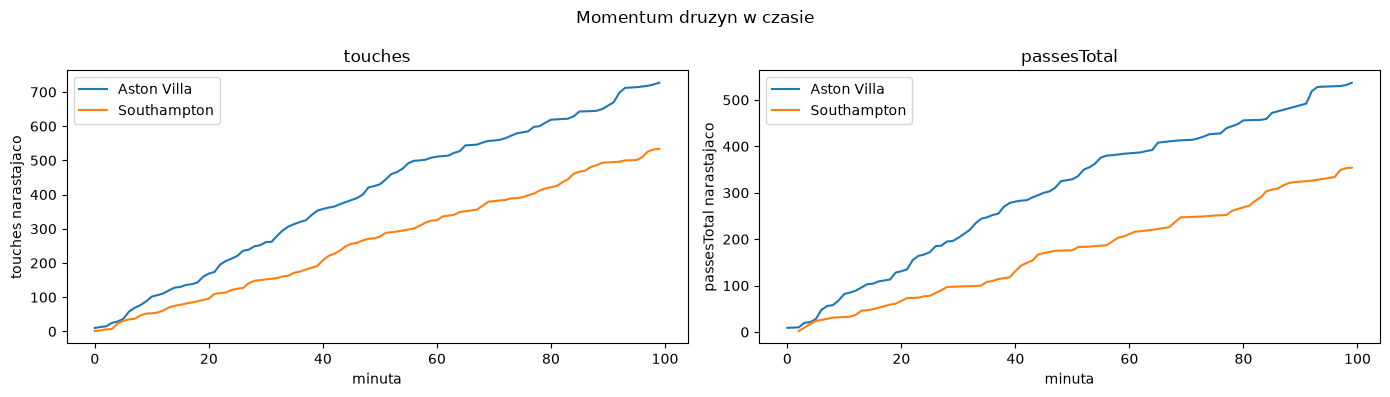

In [59]:
# Momentum druzyn: narastajace dotkniecia i podania na jednej figurze
print("metryki w team_stats:", team_stats["stat_name"].nunique())
print(team_stats["stat_name"].value_counts().head(6).to_string())
print()

# UWAGA: touches i passesTotal to PRZYROSTY na minute -> cumsum().
# 'ratings' to wartosc narastajaca (snapshot) - tego nie sumujemy.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, metric in zip(axes, ["touches", "passesTotal"]):
    for team_name, team_df in team_stats[team_stats["stat_name"] == metric].groupby("team_name"):
        team_df = team_df.sort_values("minute")
        ax.plot(team_df["minute"], team_df["value"].cumsum(), label=team_name)

    ax.set_xlabel("minuta")
    ax.set_ylabel(metric + " narastajaco")
    ax.set_title(metric)
    ax.legend()

plt.suptitle("Momentum druzyn w czasie")
plt.tight_layout()
plt.savefig(FIGURES / "momentum.png", dpi=120)
plt.show()


In [60]:
# Okna 5-minutowe: kto mial przewage w danym fragmencie meczu
windows_df = team_stats[team_stats["stat_name"] == "touches"].copy()
windows_df["window_start"] = (windows_df["minute"] // 5) * 5

window_table = windows_df.groupby(["window_start", "team_name"])["value"].sum().unstack()

print("dotkniecia pilki w oknach 5-minutowych:")
print(window_table.head(12).to_string())

if window_table.shape[1] == 2:
    diff_series = window_table.iloc[:, 0] - window_table.iloc[:, 1]
    print()
    print("przewaga (", window_table.columns[0], "-", window_table.columns[1], "):")
    print(diff_series.head(12).to_string())


dotkniecia pilki w oknach 5-minutowych:
team_name     Aston Villa  Southampton
window_start                          
0                    29.0         23.0
5                    59.0         29.0
10                   40.0         23.0
15                   32.0         17.0
20                   53.0         29.0
25                   39.0         29.0
30                   55.0         13.0
35                   46.0         28.0
40                   19.0         58.0
45                   53.0         23.0
50                   51.0         23.0
55                   32.0         29.0

przewaga ( Aston Villa - Southampton ):
window_start
0      6.0
5     30.0
10    17.0
15    15.0
20    24.0
25    10.0
30    42.0
35    18.0
40   -39.0
45    30.0
50    28.0
55     3.0


## 12. Rzuty karne

`is_penalty` flaguje całą sytuację (faul, kartka, `PenaltyFaced`), nie sam strzał. Sekwencje przed karnym.


In [61]:
# Rzuty karne - UWAGA: is_penalty to flaga CALEJ SYTUACJI, nie strzal z karnego.
# Flaga obejmuje faul, kartke i PenaltyFaced bramkarza.
penalty_shots = ev[ev["is_penalty"] & ev["has_shot"]]

print("zdarzen z flaga is_penalty:", int(ev["is_penalty"].sum()))
print("z tego strzalow z karnego :", len(penalty_shots))
print("z tego goli               :", int(penalty_shots["has_goal"].sum()))
print()

penalties_per_match = penalty_shots.groupby("match_id").size()
print("meczow z rzutem karnym:", len(penalties_per_match), "z", ev["match_id"].nunique())
print(penalties_per_match.to_string())


zdarzen z flaga is_penalty: 26
z tego strzalow z karnego : 6
z tego goli               : 4

meczow z rzutem karnym: 5 z 10
match_id
1821123    2
1993983    1
1995426    1
2002449    1
2029242    1


In [62]:
# Co poprzedza strzal z karnego - 4 zdarzenia wstecz
print("=== sekwencja przed kazdym strzalem z karnego ===")

for _, shot_row in penalty_shots.iterrows():
    prev_events = ev[
        (ev["match_id"] == shot_row["match_id"])
        & (ev["event_index"] < shot_row["event_index"])
        & (ev["event_index"] >= shot_row["event_index"] - 4)
    ]

    print()
    print(f"mecz {shot_row['match_id']}, {shot_row['expanded_minute']}. min - karny: {shot_row['player_name']} ({shot_row['team_name']})")

    for _, ev_row in prev_events.iterrows():
        player_label = ev_row["player_name"] if pd.notna(ev_row["player_name"]) else "-"
        print(f"   {ev_row['expanded_minute']:>3}. min  {str(ev_row['event_type']):<16} {player_label}")


=== sekwencja przed kazdym strzalem z karnego ===

mecz 1821123, 70. min - karny: Marco Asensio (Aston Villa)
    69. min  Foul             Ollie Watkins
    69. min  Foul             Jan Bednarek
    69. min  Card             Jan Bednarek
    70. min  PenaltyFaced     Aaron Ramsdale

mecz 1821123, 95. min - karny: Marco Asensio (Aston Villa)
    93. min  BallTouch        Donyell Malen
    93. min  Foul             John McGinn
    93. min  Foul             Jack Stephens
    95. min  PenaltyFaced     Aaron Ramsdale

mecz 1993983, 10. min - karny: Kylian Mbappé (Real Madrid)
     9. min  Pass             Yan Diomande
     9. min  TakeOn           Kylian Mbappé
     9. min  Foul             Kylian Mbappé
     9. min  Foul             Matteo Prati

mecz 1995426, 65. min - karny: Niclas Füllkrug (Werder Bremen)
    64. min  Pass             Mitchell Weiser
    65. min  SavedShot        Olivier Deman
    65. min  Foul             -
    65. min  Foul             Laurin Curda

mecz 2002449, 21

## 13. Big chance

Prawdopodobieństwo stuprocentowej sytuacji w zależności od cech posiadania.


In [63]:
# BIG CHANCE - doklejenie do posiadan (razem z czasem trwania)
possession_extra = ev.groupby(["match_id", "possession_id"]).agg(
    big_chance=("is_big_chance", "max"),
    duration_min=("expanded_minute", lambda s: s.max() - s.min()),
).reset_index()

possessions = possessions.merge(possession_extra, on=["match_id", "possession_id"], how="left")

print("big chance w zbiorze zdarzen:", int(ev["is_big_chance"].sum()))
print("posiadan z big chance      :", int(possessions["big_chance"].sum()))
print()

for col in ["box_entry", "passes_bin", "start_zone"]:
    print(f"=== P(big_chance) wg {col} ===")
    print(cond_table(possessions, col, target="big_chance").to_string())
    print()


big chance w zbiorze zdarzen: 49
posiadan z big chance      : 49

=== P(big_chance) wg box_entry ===
           cases  hits   P %   95% CI
box_entry                            
False       4625    37  0.80  0.6-1.1
True         449    12  2.67  1.5-4.6

=== P(big_chance) wg passes_bin ===
            cases  hits   P %   95% CI
passes_bin                            
0            2378    19  0.80  0.5-1.2
1             993     7  0.70  0.3-1.4
2             456     6  1.32  0.6-2.8
3-4           486     3  0.62  0.2-1.8
5-8           435     8  1.84  0.9-3.6
9+            326     6  1.84  0.8-4.0

=== P(big_chance) wg start_zone ===
             cases  hits   P %   95% CI
start_zone                             
own_third     1976     4  0.20  0.1-0.5
mid_third     1849    17  0.92  0.6-1.5
final_third   1129    28  2.48  1.7-3.6



## 14. Ranking cech per cel

Osobny ranking par cech dla każdego celu: strzał, gol, big chance.


In [64]:
# Ranking par cech dla KAZDEGO celu osobno (poziom posiadania).
# Funkcja plane_r2 jest zdefiniowana w sekcji 1.
possession_features = ["passes_count", "events_count", "start_x", "duration_min", "box_entry"]
possession_targets = ["has_shot", "has_goal", "big_chance"]

for target_col in possession_targets:
    target_pairs = []

    for x1, x2 in itertools.combinations([k for k in possession_features if k != target_col], 2):
        sub_df = possessions[[x1, x2, target_col]].dropna()
        if len(sub_df) < 50:
            continue
        target_pairs.append((plane_r2(sub_df, x1, x2, target_col), x1, x2))

    target_pairs.sort(key=lambda t: -t[0])

    print(f"=== TOP 3 pary cech dla celu '{target_col}' (posiadan: {len(possessions)}) ===")
    for r2, x1, x2 in target_pairs[:3]:
        print(f"  {target_col:<12} ~ {x1:<12} + {x2:<12} R2 = {r2:.4f}")
    print()


=== TOP 3 pary cech dla celu 'has_shot' (posiadan: 5074) ===
  has_shot     ~ events_count + start_x      R2 = 0.0606
  has_shot     ~ start_x      + duration_min R2 = 0.0568
  has_shot     ~ passes_count + start_x      R2 = 0.0542

=== TOP 3 pary cech dla celu 'has_goal' (posiadan: 5074) ===
  has_goal     ~ start_x      + duration_min R2 = 0.0104
  has_goal     ~ events_count + start_x      R2 = 0.0092
  has_goal     ~ passes_count + events_count R2 = 0.0077

=== TOP 3 pary cech dla celu 'big_chance' (posiadan: 5074) ===
  big_chance   ~ events_count + start_x      R2 = 0.0124
  big_chance   ~ passes_count + events_count R2 = 0.0107
  big_chance   ~ start_x      + duration_min R2 = 0.0101



## Ograniczenia


**Czołowe trójki są geometryczne i zaśmiecone licznikami.** `goal_distance` jest wyliczony
z `x` i `y`, więc `goal_distance ~ x + y` daje R² = 0,89 z definicji. Podobnie `x ↔ end_x` (r = 0,81) —
pozycja końcowa podania leży blisko startowej. W rankingu są też `second` (sekunda w minucie)
i `event_type_value` (kod typu zdarzenia): to liczniki, nie cechy gry, więc ich miejsca w TOP-10
nic nie znaczą. Całość traktuj jako rozpoznanie danych, nie wynik.
